# Kokoro step by step — Part 2: substitution and B4 continua in a long utterance

Question: if one phoneme changes (t → d, t → θ …), how much of the change sits on that
token, and how much spreads to its neighbours through the encoder's context?

**Setup.** Two versions of the same ~150-token utterance:
* **A** = original (`… litˈalja …`)
* **B** = same string with the target `t` replaced (`… lidˈalja …`)

Both go through the acoustic encoder (step 10), giving one 512-number vector per token for each.
Everything else (durations, alignment, pitch, energy, voice) is taken from **A**, so the
**only** thing that differs between conditions is the step-10 vectors.

**Experiment 1 — substitution**
* `A` original
* `isolated`: A's vectors everywhere, B's vector **only at the target token**
* `context`: B's vectors everywhere (the neighbours re-encoded knowing the target is now d)
* `B natural`: B with its own prosody too, for reference

**Experiment 2 — B4 continuum** between A's and B's step-10 vectors, `(1−α)·A + α·B`,
applied to the target token only, a window of ±k neighbours, or the whole utterance.

In [1]:
import os
import numpy as np
import torch
import soundfile as sf
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from kokoro import KModel

device = "cuda" if torch.cuda.is_available() else "cpu"
model = KModel().to(device).eval()
vocab = model.vocab
SR, HOP = 24000, 600            # 24 kHz; one alignment frame = 600 samples = 25 ms
OUT = "part2_out"; os.makedirs(OUT, exist_ok=True)

def load_voice(name):
    path = hf_hub_download("hexgrad/Kokoro-82M", f"voices/{name}.pt")
    return torch.load(path, weights_only=True).to(device)

c:\Users\gmoha\anaconda3\envs\kokoro\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


c:\Users\gmoha\anaconda3\envs\kokoro\Lib\site-packages\torch\nn\modules\rnn.py:1011: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)
c:\Users\gmoha\anaconda3\envs\kokoro\Lib\site-packages\torch\nn\utils\weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


## The pipeline steps (same as Part 1)

In [2]:
@torch.no_grad()
def step1_tokenize(ps):
    missing = sorted({p for p in ps if p not in vocab})
    assert not missing, f"not in Kokoro's vocab (would be dropped): {missing}"
    return torch.LongTensor([[0, *[vocab[p] for p in ps], 0]]).to(device)

def step2_voice(pack, ps):
    ref_s = pack[len(ps) - 1]
    return ref_s[:, 128:], ref_s[:, :128]                    # prosody style, timbre

@torch.no_grad()
def step3_4_prosody_text(ids):
    mask = torch.zeros_like(ids, dtype=torch.bool)
    return model.bert_encoder(model.bert(ids, attention_mask=(~mask).int())).transpose(-1, -2)

@torch.no_grad()
def step5_duration_encoder(d_en, style, ids):
    L = torch.LongTensor([ids.shape[-1]]).to(device)
    return model.predictor.text_encoder(d_en, style, L, torch.zeros_like(ids, dtype=torch.bool))

@torch.no_grad()
def step6_durations(d, speed=1.0):
    x, _ = model.predictor.lstm(d)
    dur = torch.sigmoid(model.predictor.duration_proj(x)).sum(-1) / speed
    return torch.round(dur).clamp(min=1).long().squeeze(0)

def step7_alignment(pred_dur):
    pred_dur = pred_dur.clamp(min=0)
    T = int(pred_dur.sum())
    aln = torch.zeros(len(pred_dur), T, device=device)
    idx = torch.repeat_interleave(torch.arange(len(pred_dur), device=device), pred_dur.to(device))
    aln[idx, torch.arange(T, device=device)] = 1
    return aln.unsqueeze(0)

@torch.no_grad()
def step8_pitch_energy(d, aln, style):
    return model.predictor.F0Ntrain(d.transpose(-1, -2) @ aln, style)

@torch.no_grad()
def step9_10_acoustic(ids):
    L = torch.LongTensor([ids.shape[-1]]).to(device)
    return model.text_encoder(ids, L, torch.zeros_like(ids, dtype=torch.bool))   # [1, 512, tokens]

@torch.no_grad()
def step12_decode(asr, F0, N, timbre):
    return model.decoder(asr, F0, N, timbre).squeeze().cpu()

# Two helpers on top: encode() runs steps 1-10, render() runs 11-12 with any step-10 vectors.
@torch.no_grad()
def encode(ps, pack, speed=1.0):
    ids = step1_tokenize(ps)
    style, timbre = step2_voice(pack, ps)
    d = step5_duration_encoder(step3_4_prosody_text(ids), style, ids)
    pred_dur = step6_durations(d, speed)
    aln = step7_alignment(pred_dur)
    F0, N = step8_pitch_energy(d, aln, style)
    return dict(ps=ps, ids=ids, timbre=timbre, pred_dur=pred_dur, aln=aln, F0=F0, N=N,
                t_en=step9_10_acoustic(ids))

@torch.no_grad()
def render(t_en, P, seed=0):
    """Decode step-10 vectors t_en using the prosody/alignment/voice of encoding P."""
    torch.manual_seed(seed)                 # decoder adds noise: same seed for every condition
    return step12_decode(t_en @ P["aln"], P["F0"], P["N"], P["timbre"])

## The carrier utterance (~150 tokens, several t's)

Written directly in Kokoro's IPA (Italian, espeak-style). You can replace it with your own,
or generate one from text with `text_to_phonemes` (needs espeak-ng installed).
Keep the stress mark `ˈ` before the stressed syllable and check every symbol is in the vocab.

In [3]:
def text_to_phonemes(text, lang_code="i"):
    """Optional: Kokoro's own G2P (lang 'i' = Italian via espeak-ng)."""
    from kokoro import KPipeline
    pipe = KPipeline(lang_code=lang_code, model=False)
    return " ".join(r.phonemes for r in pipe(text))

# "Nell'estate del duemila, Tito ha visitato l'Italia con tutta la sua famiglia,
#  e ha trovato tanti posti stupendi vicino al mare."
PS_A = ("nellestˈate del duemˈila, tˈito a vizitˈato litˈalja kon tˈutta la sˈua famˈiʎʎa, "
        "e a trovˈato tˈanti pˈɔsti stupˈɛndi viʧˈino al mˈare.")
VOICE = "if_sara"          # Italian voice; try "im_nicola" or "af_heart"
pack = load_voice(VOICE)
print(len(PS_A), "phonemes ->", len(PS_A) + 2, "tokens")

def show_occurrences(ps, sym):
    """List every occurrence of sym with its index and a bit of context."""
    for i, p in enumerate(ps):
        if p == sym:
            print(f"index {i:3d}: …{ps[max(0, i-8):i]}[{p}]{ps[i+1:i+9]}…")
show_occurrences(PS_A, "t")

def locate(ps, word, sym):
    """Index of `sym` inside the first occurrence of `word` in ps."""
    start = ps.index(word)
    return start + word.index(sym)

136 phonemes -> 138 tokens
index   6: …nelles[t]ˈate del…
index   9: …ellestˈa[t]e del du…
index  26: …emˈila, [t]ˈito a v…
index  29: …ila, tˈi[t]o a vizi…
index  38: …o a vizi[t]ˈato lit…
index  41: … vizitˈa[t]o litˈal…
index  46: …tˈato li[t]ˈalja ko…
index  57: …lja kon [t]ˈutta la…
index  60: … kon tˈu[t]ta la sˈ…
index  61: …kon tˈut[t]a la sˈu…
index  86: …ʎa, e a [t]rovˈato …
index  92: …a trovˈa[t]o tˈanti…
index  95: …rovˈato [t]ˈanti pˈ…
index  99: …ato tˈan[t]i pˈɔsti…
index 106: …nti pˈɔs[t]i stupˈɛ…
index 110: …pˈɔsti s[t]upˈɛndi …


## Choose target(s) and substitute

`TARGETS` are phoneme indices (positions in the string). Token position = index + 1
(because of the start pad). Use one target, or all t's: `[i for i,p in enumerate(PS_A) if p=='t']`.
Any single-character substitute works: `"d"`, `"θ"`, `"ʈ"`, `"ʨ"` …

In [8]:
TARGETS = [locate(PS_A, "litˈalja", "t")]       # the t of "Italia"
SUB = "θ"                                         # try "θ", "ʈ", "ʨ"

def substitute(ps, targets, new):
    s = list(ps)
    for i in targets:
        s[i] = new
    return "".join(s)

PS_B = substitute(PS_A, TARGETS, SUB)
tok = [i + 1 for i in TARGETS]                    # token positions of the targets
print("A:", PS_A[TARGETS[0]-10:TARGETS[0]+10])
print("B:", PS_B[TARGETS[0]-10:TARGETS[0]+10])

A = encode(PS_A, pack)
B = encode(PS_B, pack)
print("same length -> same voice row and same number of tokens:", A["t_en"].shape == B["t_en"].shape)

A: zitˈato litˈalja kon
B: zitˈato liθˈalja kon
same length -> same voice row and same number of tokens: True


## How far does the change spread inside the encoder?

For every token: cosine distance between its step-10 vector in A and in B.
Only the target symbol changed, so any distance on other tokens is the
context effect (coarticulation the encoder learned).

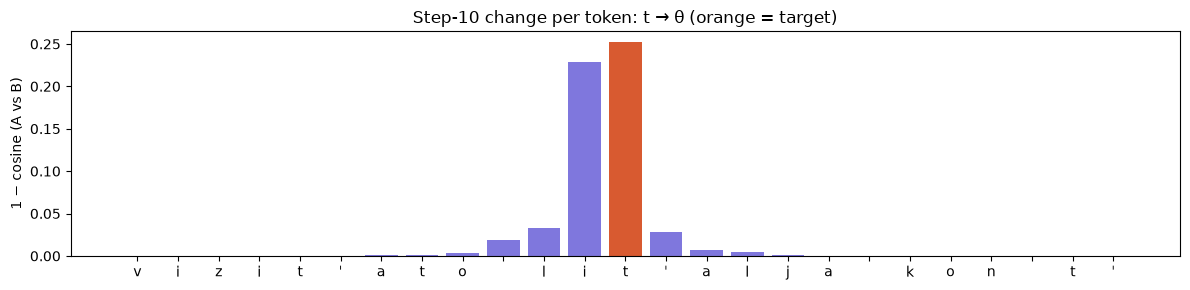

±1: 'i' 0.229   'ˈ' 0.029
±2: 'l' 0.033   'a' 0.007
±3: ' ' 0.019   'l' 0.005
±4: 'o' 0.004   'j' 0.001
±5: 't' 0.001   'a' 0.000
±6: 'a' 0.001   ' ' 0.000
target: 0.252 | mean of tokens > 6 away: 0.0000


In [ ]:
cosd = 1 - torch.nn.functional.cosine_similarity(A["t_en"][0], B["t_en"][0], dim=0).cpu().numpy()
labels = ["<s>", *PS_A, "</s>"]
lo, hi = max(0, tok[0] - 12), min(len(labels), tok[0] + 13)
 
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(range(lo, hi), cosd[lo:hi], color=["#D85A30" if i in tok else "#7F77DD" for i in range(lo, hi)])
ax.set_xticks(range(lo, hi)); ax.set_xticklabels(labels[lo:hi])
ax.set_ylabel("1 − cosine (A vs B)")
ax.set_title(f"Step-10 change per token: {PS_A[TARGETS[0]]} → {SUB} (orange = target)")
plt.tight_layout(); plt.savefig(f"{OUT}/spread_encoder.png", dpi=120); plt.show()

for k in range(1, 7):
    left, right = tok[0] - k, tok[0] + k
    print(f"±{k}: {labels[left]!r} {cosd[left]:.3f}   {labels[right]!r} {cosd[right]:.3f}")
print(f"target: {cosd[tok[0]]:.3f} | mean of tokens > 6 away: "
      f"{np.mean([c for i, c in enumerate(cosd) if all(abs(i - t) > 6 for t in tok)]):.4f}")

## Spectrogram tools

All conditions in Experiments 1 and 2 share A's alignment, so they have the same length
and can be subtracted frame by frame. The difference plot shows exactly where in time
the change lands. Dashed lines = boundaries of the target token.

In [10]:
def spec_db(audio, n_fft=1024, hop=120):
    x = audio if torch.is_tensor(audio) else torch.tensor(audio)
    S = torch.stft(x.float(), n_fft, hop, window=torch.hann_window(n_fft), return_complex=True).abs()
    return (20 * torch.log10(S + 1e-5)).numpy(), hop

def token_times(P):
    ends = torch.cumsum(P["pred_dur"].cpu(), 0) * HOP / SR
    return (ends - P["pred_dur"].cpu() * HOP / SR).numpy(), ends.numpy()

def zoom_window(P, positions, pad_tokens=8):
    st, en = token_times(P)
    return st[max(0, min(positions) - pad_tokens)], en[min(len(en) - 1, max(positions) + pad_tokens)]

def plot_specs(audios, P, positions, ref_key=None, fmax=8000, title="", fname=None, pad_tokens=8):
    """audios: {name: waveform}. If ref_key is given, adds a difference row (cond − ref) under each."""
    t0, t1 = zoom_window(P, positions, pad_tokens)
    st, en = token_times(P)
    names = list(audios)
    rows = 2 if ref_key else 1
    fig, axes = plt.subplots(rows, len(names), figsize=(3.6 * len(names), 3 * rows), squeeze=False)
    ref_db = spec_db(audios[ref_key])[0] if ref_key else None
    for j, n in enumerate(names):
        db, hop = spec_db(audios[n])
        ext = [0, db.shape[1] * hop / SR, 0, SR / 2]
        ax = axes[0, j]
        ax.imshow(db, origin="lower", aspect="auto", extent=ext, cmap="magma", vmin=db.max() - 80, vmax=db.max())
        ax.set_title(n, fontsize=10)
        if ref_key:
            dd = db - ref_db
            axd = axes[1, j]
            axd.imshow(dd, origin="lower", aspect="auto", extent=ext, cmap="RdBu_r", vmin=-20, vmax=20)
            axd.set_title(f"{n} − {ref_key} (dB)", fontsize=9)
        for r in range(rows):
            a = axes[r, j]
            a.set_xlim(t0, t1); a.set_ylim(0, fmax)
            for p in positions:
                a.axvline(st[p], color="w" if r == 0 else "k", ls="--", lw=0.8)
                a.axvline(en[p], color="w" if r == 0 else "k", ls="--", lw=0.8)
            # phoneme labels under the axis
            mids = [(st[i] + en[i]) / 2 for i in range(len(st))]
            vis = [i for i in range(len(st)) if t0 <= mids[i] <= t1]
            a.set_xticks([mids[i] for i in vis]); a.set_xticklabels([labels[i] for i in vis], fontsize=8)
    axes[0, 0].set_ylabel("Hz")
    fig.suptitle(title); plt.tight_layout()
    if fname: plt.savefig(f"{OUT}/{fname}", dpi=120)
    plt.show()

def audio_change(audio, ref, P, positions, radius_tokens=3):
    """Mean |dB difference| inside the target token(s) vs. in the neighbouring tokens."""
    dd = np.abs(spec_db(audio)[0] - spec_db(ref)[0])
    st, en = token_times(P); hop = 120
    def frames(i): return slice(int(st[i] * SR / hop), int(en[i] * SR / hop) + 1)
    inside = np.mean([dd[:, frames(p)].mean() for p in positions])
    neigh = [i for p in positions for i in range(p - radius_tokens, p + radius_tokens + 1)
             if i not in positions and 0 <= i < len(st)]
    outside = np.mean([dd[:, frames(i)].mean() for i in neigh])
    return inside, outside

## Experiment 1 — substitution: isolated vs. with re-encoded neighbours

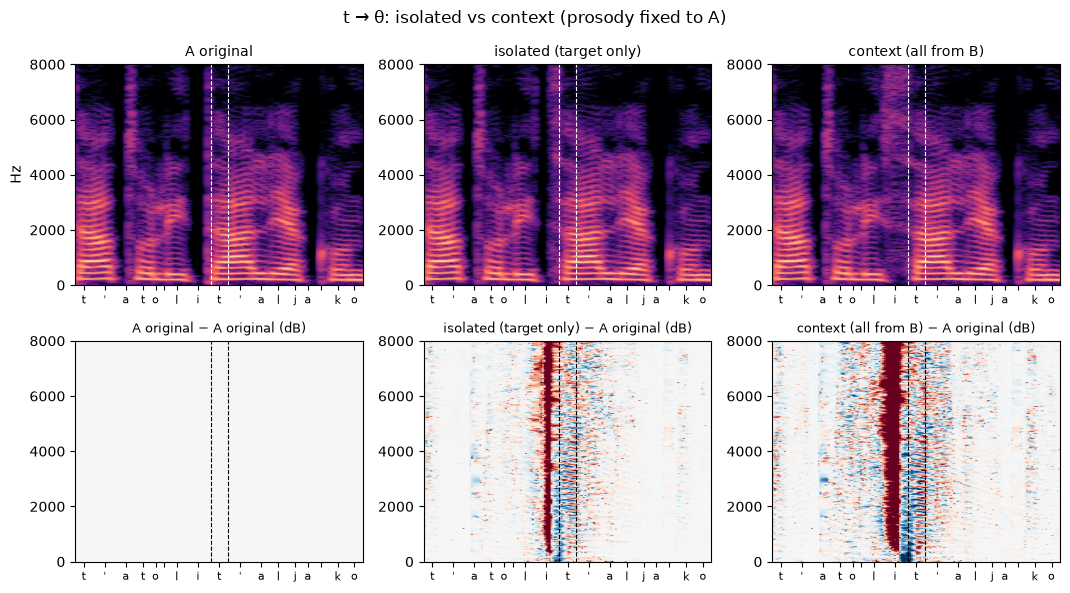

  isolated (target only): mean |ΔdB| target 6.40 | neighbours ±3 3.71
    context (all from B): mean |ΔdB| target 7.88 | neighbours ±3 6.74


In [11]:
iso = A["t_en"].clone()
iso[:, :, tok] = B["t_en"][:, :, tok]           # only the target token's vector from B

exp1 = {
    "A original": render(A["t_en"], A),
    "isolated (target only)": render(iso, A),
    "context (all from B)": render(B["t_en"], A),
}
b_nat = render(B["t_en"], B)                    # B with its own timing/pitch (different length)

for name, audio in exp1.items():
    sf.write(f"{OUT}/exp1_{name.split()[0]}.wav", audio.numpy(), SR)
sf.write(f"{OUT}/exp1_B_natural.wav", b_nat.numpy(), SR)

plot_specs(exp1, A, tok, ref_key="A original",
           title=f"{PS_A[TARGETS[0]]} → {SUB}: isolated vs context (prosody fixed to A)",
           fname="exp1_substitution.png")

for name in ["isolated (target only)", "context (all from B)"]:
    i_, o_ = audio_change(exp1[name], exp1["A original"], A, tok)
    print(f"{name:>24}: mean |ΔdB| target {i_:.2f} | neighbours ±3 {o_:.2f}")

In [12]:
# ---------- Diagnostics ----------
# 1) Do A and B really get different token ids at the target?
print("target tokens:", tok)
print("A ids at target:", A["ids"][0, tok].tolist(), "->", [PS_A[i] for i in TARGETS])
print("B ids at target:", B["ids"][0, tok].tolist(), "->", [PS_B[i] for i in TARGETS])
print("vocab:", {s: vocab.get(s) for s in ["t", "d", "θ"]})

# 2) Do the step-10 vectors differ at the target?
print("‖A−B‖ at target:", (A["t_en"][0, :, tok] - B["t_en"][0, :, tok]).norm().item(),
      "| ‖A‖:", A["t_en"][0, :, tok].norm().item())

# 3) Is "B natural" identical to stock Kokoro for PS_B?
torch.manual_seed(0)
stock_B = model(PS_B, pack[len(PS_B) - 1])
print("B natural == stock Kokoro:", b_nat.shape == stock_B.shape and torch.allclose(b_nat, stock_B, atol=1e-4))

# 4) Are the A and B-natural waveforms different at all?
print("durations at target  A:", A["pred_dur"][tok].tolist(), " B:", B["pred_dur"][tok].tolist())
print("total length A:", len(exp1["A original"]), " B natural:", len(b_nat))

# 5) Listening excerpts: just the word, so a single consonant isn't lost in a 9-second sentence
def excerpt(audio, P, positions, pad_tokens=5):
    t0, t1 = zoom_window(P, positions, pad_tokens)
    return audio[int(t0 * SR):int(t1 * SR)]
sil = torch.zeros(int(0.4 * SR))
pair = torch.cat([excerpt(exp1["A original"], A, tok), sil, excerpt(b_nat, B, tok)])
sf.write(f"{OUT}/listen_A_then_Bnatural.wav", pair.numpy(), SR)

# 6) Short-context control: can this voice make the contrast at all?
for v in [VOICE, "af_heart"]:
    pk = load_voice(v)
    seq = []
    for w in ["litˈalja", f"li{SUB}ˈalja"]:
        torch.manual_seed(0)
        seq += [model(w, pk[len(w) - 1]), sil]
    sf.write(f"{OUT}/short_{v}.wav", torch.cat(seq).numpy(), SR)
print("saved listen_A_then_Bnatural.wav and short_*.wav")

target tokens: [47]
A ids at target: [62] -> ['t']
B ids at target: [119] -> ['θ']
vocab: {'t': 62, 'd': 46, 'θ': 119}
‖A−B‖ at target: 5.906466484069824 | ‖A‖: 8.359171867370605
B natural == stock Kokoro: True
durations at target  A: [2]  B: [2]
total length A: 190200  B natural: 187800
saved listen_A_then_Bnatural.wav and short_*.wav


## Experiment 2 — B4 continuum between A and B

`(1−α)·A + α·B` on the step-10 vectors, with the length of each mixed vector kept
(`keep_norm=True`), applied over different scopes:
* `token`: only the target; neighbours stay as encoded for A
* `±k`: the target and k neighbours on each side
* `all`: every token (= merging the two whole encodings)

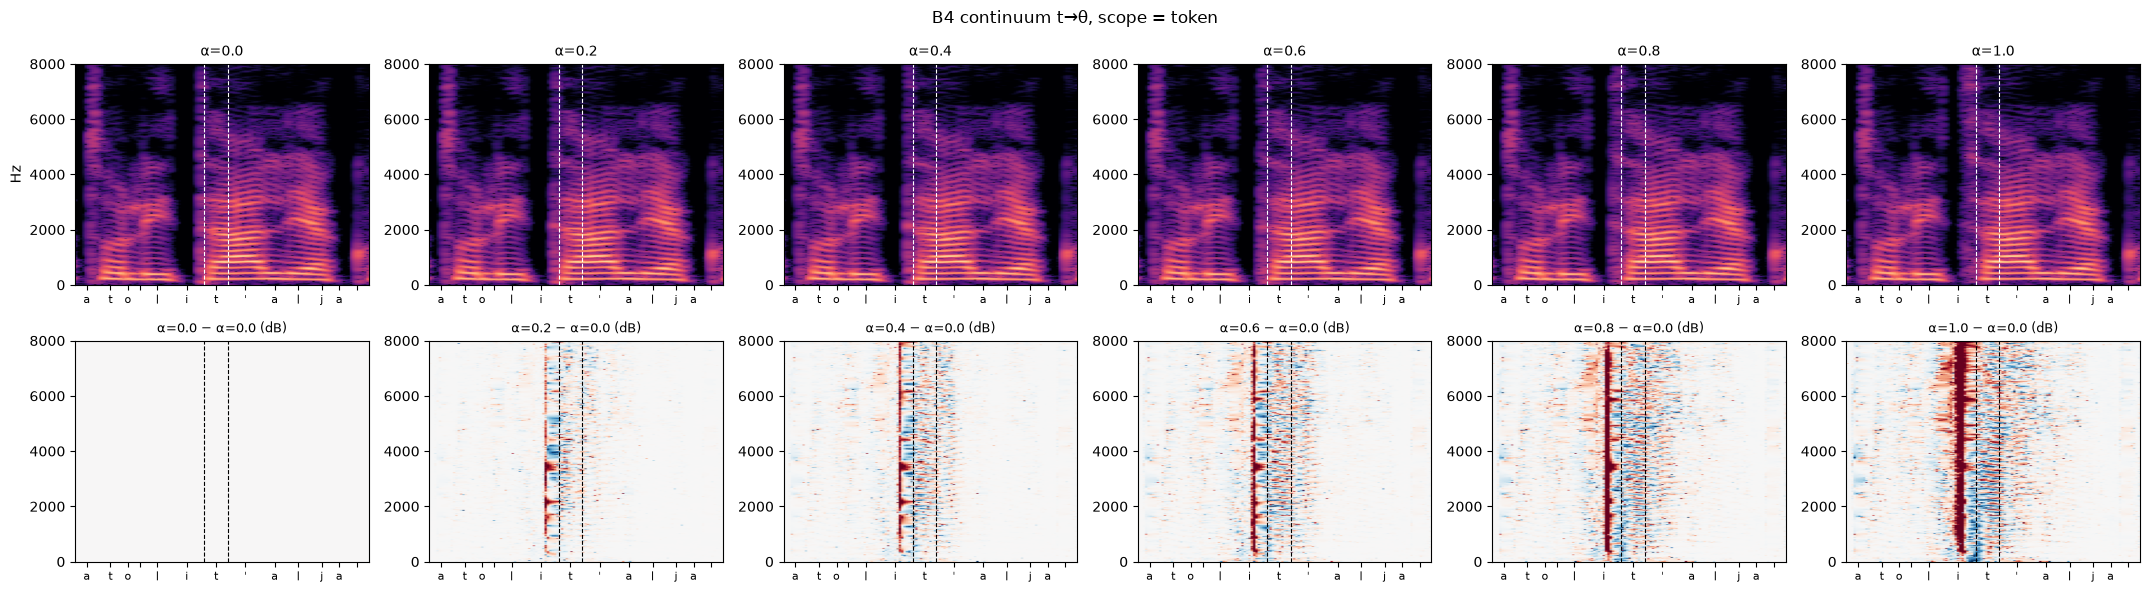

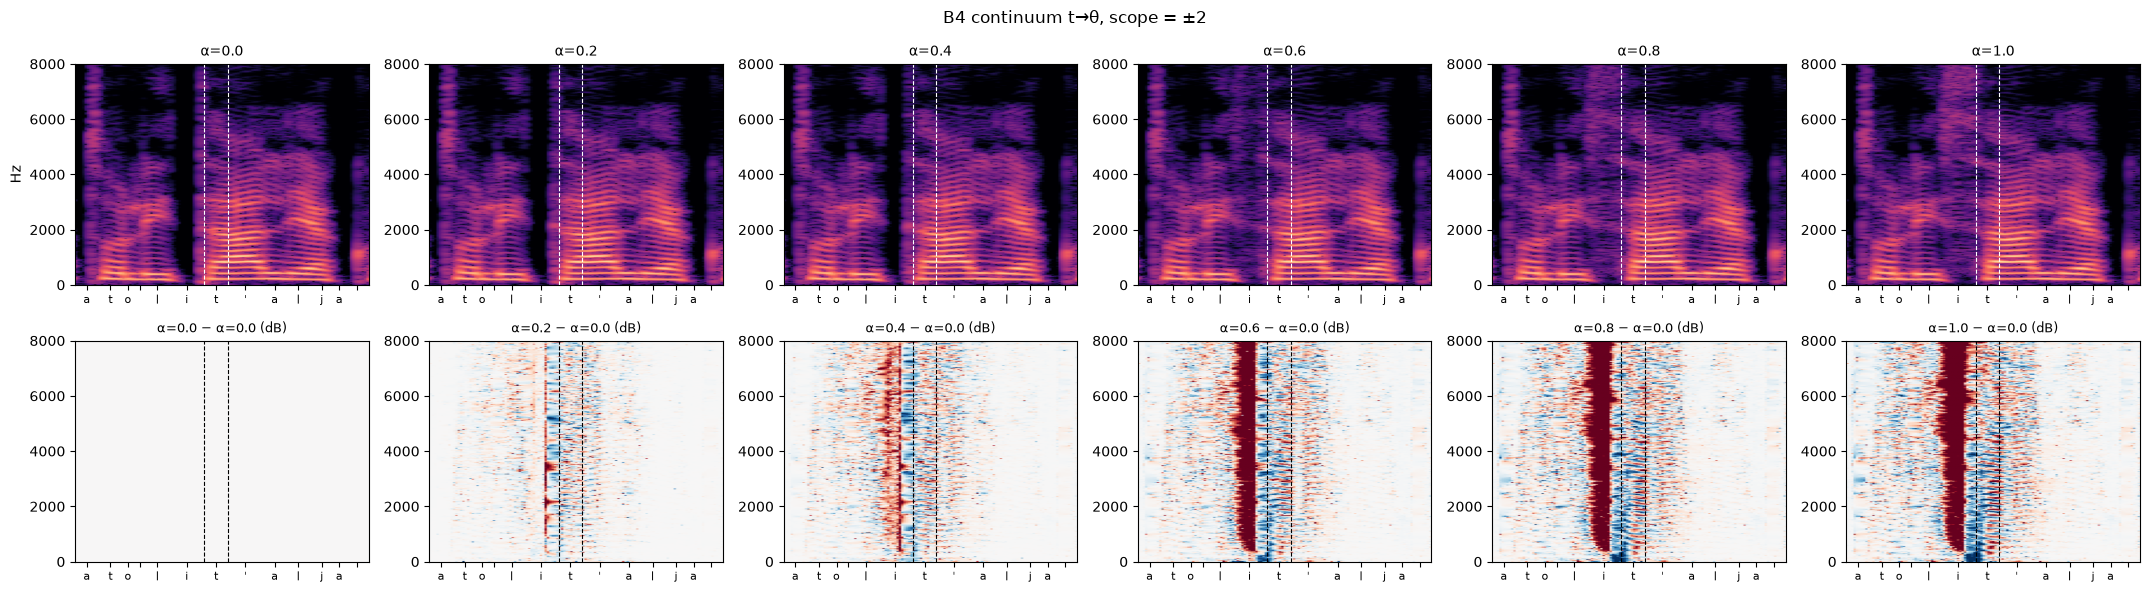

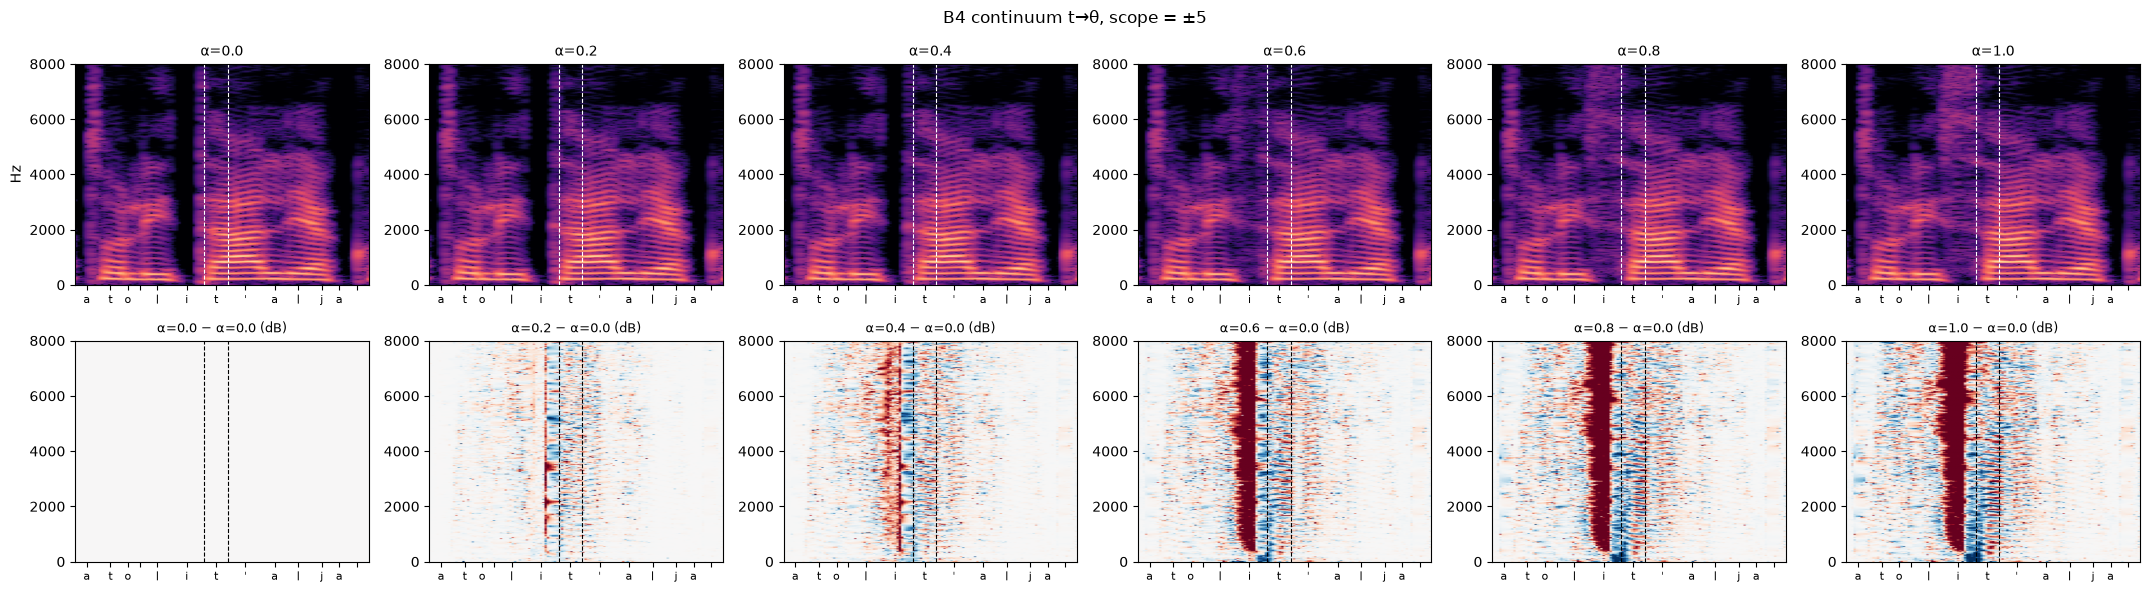

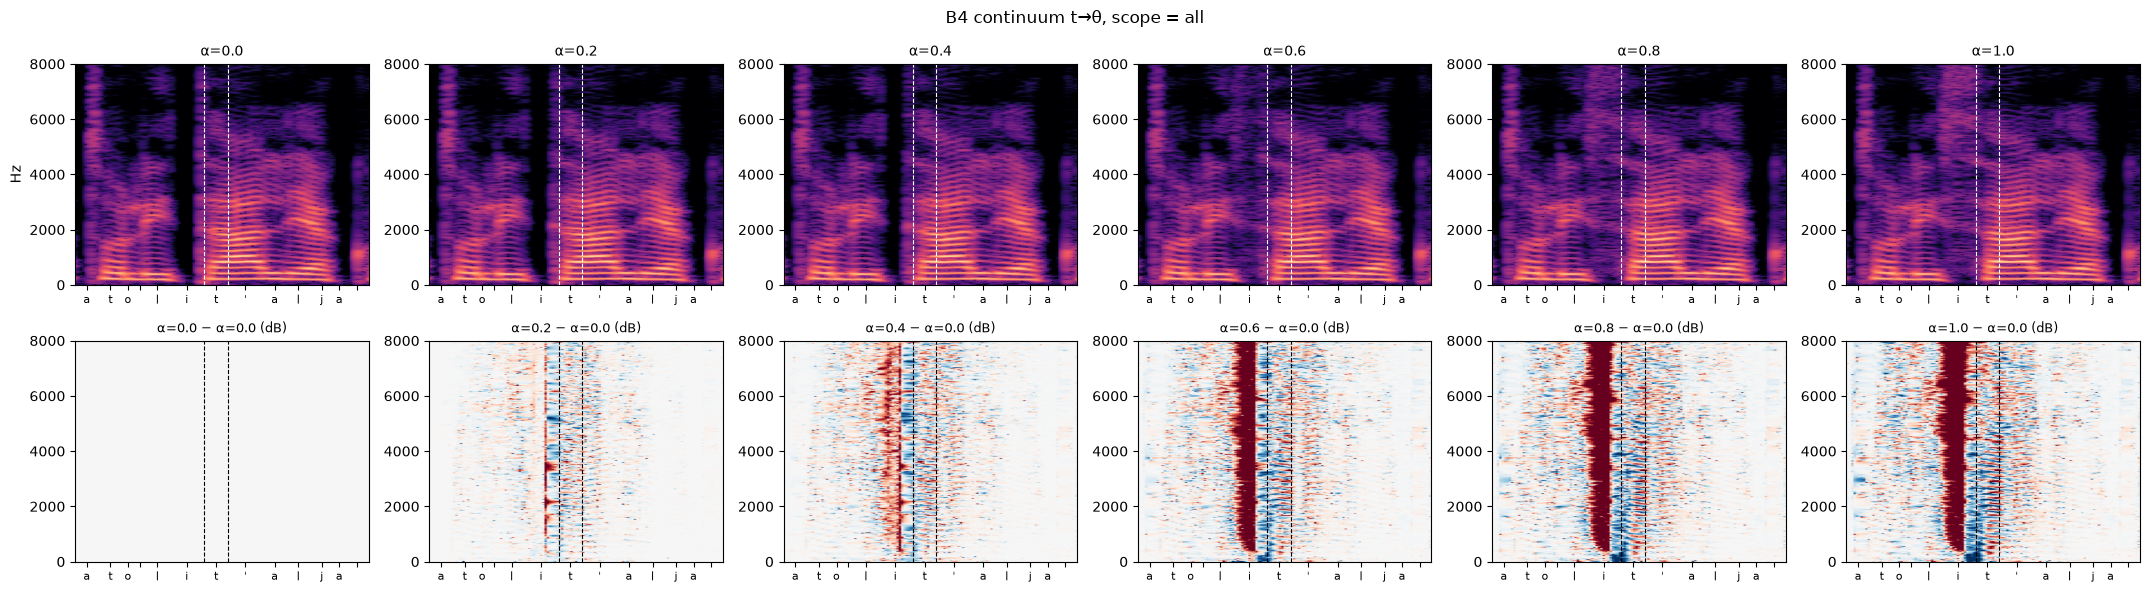

In [13]:
def blend(tA, tB, alpha, positions, keep_norm=True):
    out = tA.clone()
    a, b = tA[:, :, positions], tB[:, :, positions]
    v = (1 - alpha) * a + alpha * b
    if keep_norm:
        target = (1 - alpha) * a.norm(dim=1, keepdim=True) + alpha * b.norm(dim=1, keepdim=True)
        v = v * target / v.norm(dim=1, keepdim=True).clamp(min=1e-8)
    out[:, :, positions] = v
    return out

def scope_positions(scope, targets_tok, n_tokens):
    if scope == "token":
        return list(targets_tok)
    if scope == "all":
        return list(range(n_tokens))
    k = int(scope.strip("±"))
    return sorted({i for t in targets_tok for i in range(t - k, t + k + 1) if 0 <= i < n_tokens})

ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
SCOPES = ["token", "±2", "±5", "all"]
n_tok = A["t_en"].shape[-1]

cont = {}
for scope in SCOPES:
    pos = scope_positions(scope, tok, n_tok)
    for a in ALPHAS:
        audio = render(blend(A["t_en"], B["t_en"], a, pos), A)
        cont[(scope, a)] = audio
        sf.write(f"{OUT}/cont_{scope.replace('±', 'w')}_{a:.1f}.wav", audio.numpy(), SR)

for scope in SCOPES:
    plot_specs({f"α={a:.1f}": cont[(scope, a)] for a in ALPHAS}, A, tok, ref_key="α=0.0",
               title=f"B4 continuum {PS_A[TARGETS[0]]}→{SUB}, scope = {scope}",
               fname=f"exp2_{scope.replace('±', 'w')}.png", pad_tokens=6)

### How does the acoustic change grow with α, per scope?
Left: change inside the target token. Right: change in the ±3 neighbouring tokens.
A good continuum grows smoothly (roughly linearly) on the left.
`token` scope should keep the right panel near zero; wider scopes let the neighbours move too.

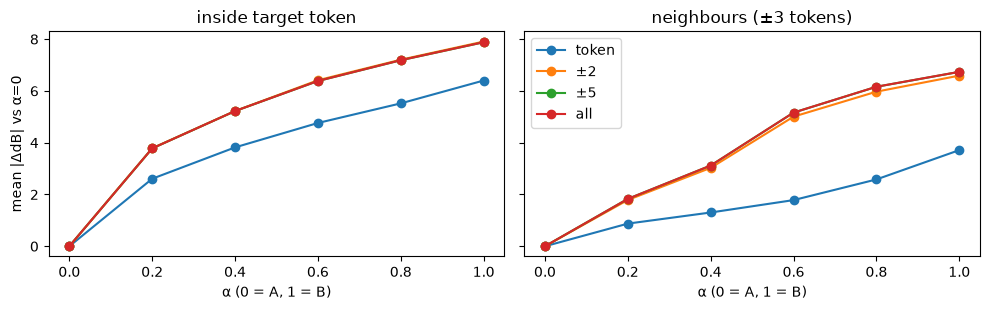

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for scope in SCOPES:
    vals = [audio_change(cont[(scope, a)], cont[(scope, 0.0)], A, tok) for a in ALPHAS]
    axes[0].plot(ALPHAS, [v[0] for v in vals], marker="o", label=scope)
    axes[1].plot(ALPHAS, [v[1] for v in vals], marker="o", label=scope)
axes[0].set_title("inside target token"); axes[1].set_title("neighbours (±3 tokens)")
for ax in axes: ax.set_xlabel("α (0 = A, 1 = B)")
axes[0].set_ylabel("mean |ΔdB| vs α=0"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/exp2_change_curves.png", dpi=120); plt.show()

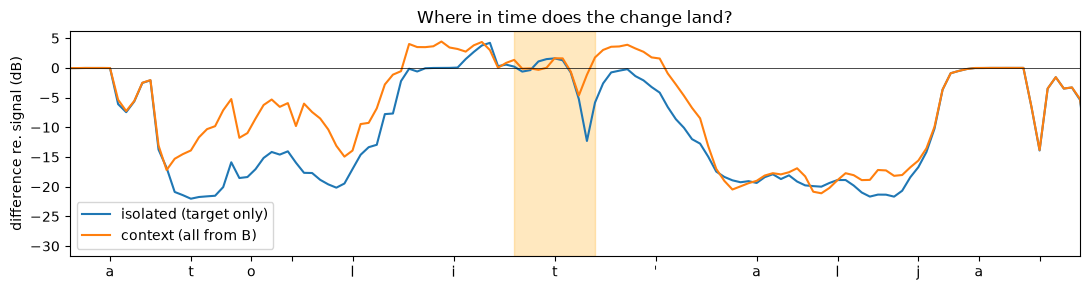

In [15]:
def diff_envelope(a, b, win_ms=5):
    """Energy of the sample-wise difference a−b, in 5 ms bins, relative to the energy of a.
    Same length required (same alignment). No STFT smearing."""
    w = int(SR * win_ms / 1000)
    n = (len(a) // w) * w
    d = ((a[:n] - b[:n]) ** 2).reshape(-1, w).mean(1)
    ref = (a[:n] ** 2).reshape(-1, w).mean(1)
    floor = ref.max() * 1e-3                       # ignore near-silent bins (−30 dB re. peak)
    return (10 * torch.log10((d + floor) / (ref + floor))).numpy(), win_ms / 1000

st, en = token_times(A)
t0, t1 = zoom_window(A, tok, 6)
fig, ax = plt.subplots(figsize=(11, 3))
for name in ["isolated (target only)", "context (all from B)"]:
    env, dt = diff_envelope(exp1["A original"], exp1[name])
    ax.plot(np.arange(len(env)) * dt, env, label=name)
for p in tok:
    ax.axvspan(st[p], en[p], color="orange", alpha=0.25)
mids = [(st[i] + en[i]) / 2 for i in range(len(st))]
vis = [i for i in range(len(st)) if t0 <= mids[i] <= t1]
ax.set_xticks([mids[i] for i in vis]); ax.set_xticklabels([labels[i] for i in vis])
ax.set_xlim(t0, t1); ax.set_ylabel("difference re. signal (dB)")
ax.axhline(0, color="k", lw=0.5)   # 0 dB = difference as loud as the signal itself
ax.legend(); ax.set_title("Where in time does the change land?"); plt.tight_layout(); plt.show()

# Same summary as before, with a finer window (256 samples ≈ 11 ms) to reduce smearing
def spec_db(audio, n_fft=256, hop=60):
    x = audio if torch.is_tensor(audio) else torch.tensor(audio)
    S = torch.stft(x.float(), n_fft, hop, window=torch.hann_window(n_fft), return_complex=True).abs()
    return (20 * torch.log10(S + S.max() * 1e-3)).numpy(), hop     # floor at −60 dB re. peak

durations in the word (frames of 25 ms):
 :1  l:2  i:3  ˈ:3  t:2  ʲ:2  a:2  l:2  j:2  a:1   :1
every column sums to 1: True


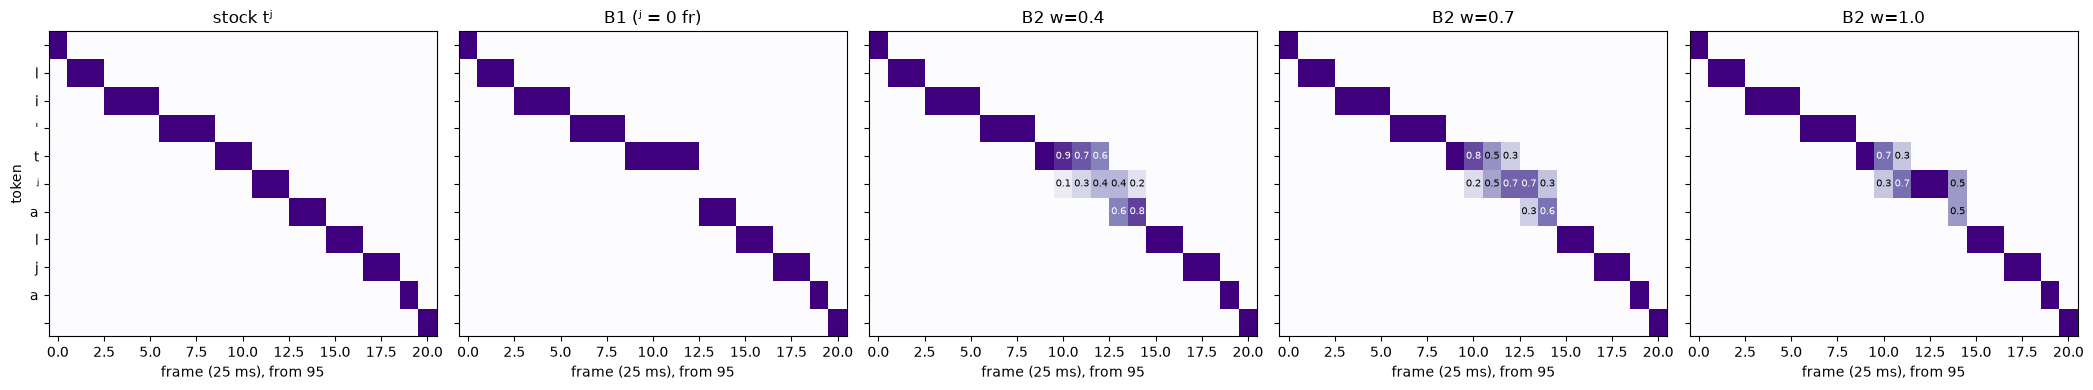

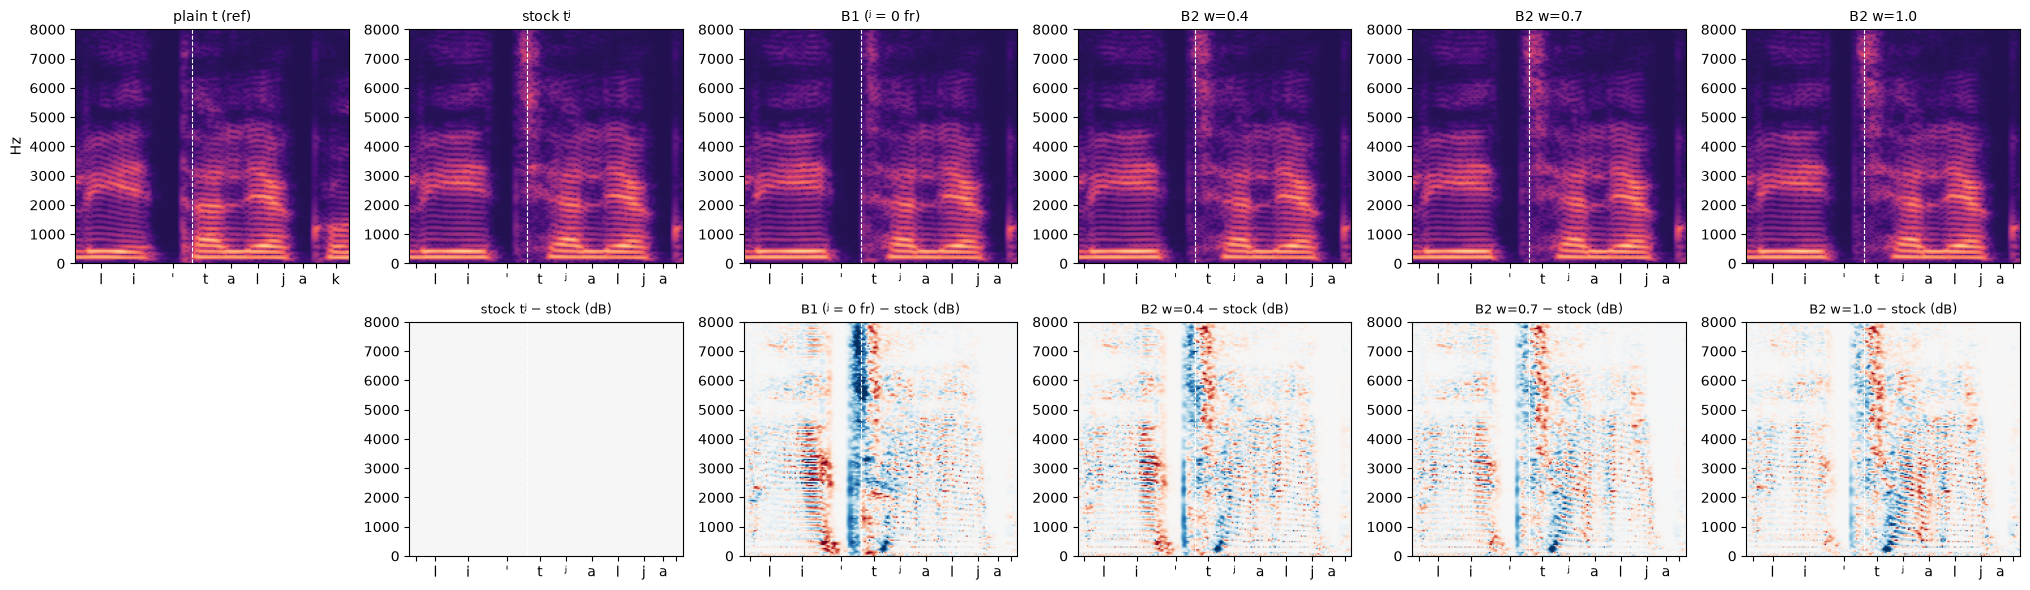

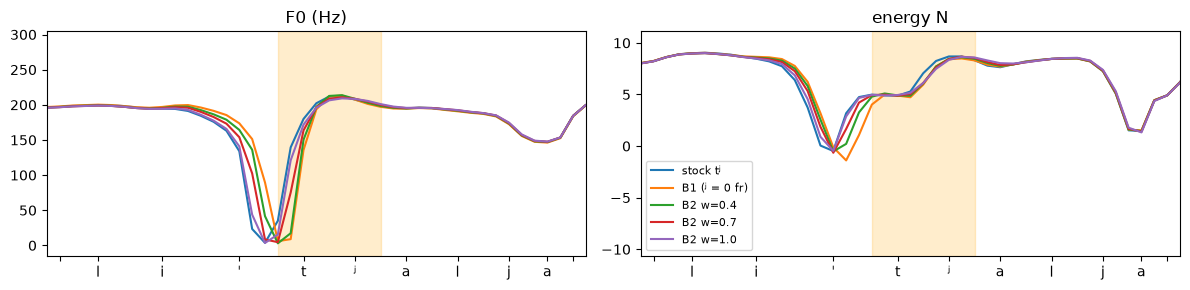

listen_b2_tj.wav: plain t (ref)  →  stock tʲ  →  B1 (ʲ = 0 fr)  →  B2 w=0.4  →  B2 w=0.7  →  B2 w=1.0


In [16]:
# %% [markdown]
# ## B2: look at the alignment matrix, then soften it for tʲ
#
# The alignment matrix is the timing schedule: rows = tokens, columns = 25 ms frames,
# cell = how much of that token's step-10 vector (and prosody features) is used in that frame.
# In stock Kokoro it is pure 0/1: each frame belongs to exactly one token, and the only
# "meaningful numbers" are the durations (how many frames each row gets).
#
# B2 replaces the 0/1 block of `t` + `ʲ` with fractional weights: ʲ gets no frames of its own,
# it is blended into t's frames (ramping up) and fades out over the vowel's first frames.
#
# Note: the stress mark is written BEFORE the syllable here (`liˈtʲalja`), so the token after
# ʲ is the vowel. The stress mark is a token with its own frames; if it sat between ʲ and a,
# the fade-out would land on the stress mark instead of the vowel.

# %%
WORD_T, WORD_TJ = "liˈtalja", "liˈtʲalja"
PS_T  = PS_A.replace("litˈalja", WORD_T, 1)      # plain t, for reference
PS_TJ = PS_A.replace("litˈalja", WORD_TJ, 1)     # tʲ version: t and ʲ are separate tokens
TOKS_TJ = ["<s>", *PS_TJ, "</s>"]
FR = HOP / SR                                     # 25 ms per alignment frame

@torch.no_grad()
def encode_full(ps, pack):
    """Steps 1-6 and 9-10. Keeps d and style so pitch/energy can be recomputed for any alignment."""
    ids = step1_tokenize(ps)
    style, timbre = step2_voice(pack, ps)
    d = step5_duration_encoder(step3_4_prosody_text(ids), style, ids)
    return dict(ps=ps, ids=ids, style=style, timbre=timbre, d=d,
                pred_dur=step6_durations(d), t_en=step9_10_acoustic(ids))

@torch.no_grad()
def render_aln(P, aln, seed=0):
    """Steps 8, 11, 12 with a given alignment: pitch/energy AND acoustic frames follow it."""
    F0, N = step8_pitch_energy(P["d"], aln, P["style"])
    torch.manual_seed(seed)
    return step12_decode(P["t_en"] @ aln, F0, N, P["timbre"]), F0, N

def spans(dur):
    ends = torch.cumsum(dur.clamp(min=0), 0)
    return (ends - dur.clamp(min=0)).tolist(), ends.tolist()

def b1_merge(dur, c, j):
    """Hard version: ʲ gets 0 frames, its frames go to the consonant (total length unchanged)."""
    d2 = dur.clone(); d2[c] += d2[j]; d2[j] = 0
    return step7_alignment(d2)

def b2_soft(dur, c, j, v, w_start=0.0, w_end=0.6, spill=3):
    """Soft alignment. c = consonant, j = ʲ, v = following vowel (token positions).
    Over the consonant's + ʲ's frames: ʲ weight ramps w_start → w_end, consonant = 1 − that.
    Over the vowel's first `spill` frames: ʲ weight fades w_end → 0, vowel = 1 − that."""
    aln = step7_alignment(dur)[0].clone()
    st, en = spans(dur)
    cs, ce = st[c], en[j]
    r = torch.linspace(w_start, w_end, ce - cs, device=aln.device)
    aln[:, cs:ce] = 0
    aln[c, cs:ce] = 1 - r
    aln[j, cs:ce] = r
    k = min(spill, en[v] - st[v])
    if k > 0:
        r2 = torch.linspace(w_end, 0, k + 1, device=aln.device)[:k]
        aln[:, st[v]:st[v] + k] = 0
        aln[j, st[v]:st[v] + k] = r2
        aln[v, st[v]:st[v] + k] = 1 - r2
    return aln.unsqueeze(0)

# --- encode the tʲ sentence once; all B2 variants reuse it (same length, same voice row) ---
P = encode_full(PS_TJ, pack)
c = PS_TJ.index(WORD_TJ) + WORD_TJ.index("t") + 1      # +1 for the start pad
j, v = c + 1, c + 2
assert TOKS_TJ[c] == "t" and TOKS_TJ[j] == "ʲ" and TOKS_TJ[v] == "a", TOKS_TJ[c:v + 1]
dur = P["pred_dur"]

ALNS = {
    "stock tʲ":      step7_alignment(dur),
    "B1 (ʲ = 0 fr)": b1_merge(dur, c, j),
    "B2 w=0.4":      b2_soft(dur, c, j, v, w_end=0.4),
    "B2 w=0.7":      b2_soft(dur, c, j, v, w_end=0.7),
    "B2 w=1.0":      b2_soft(dur, c, j, v, w_end=1.0),
}

lo, hi = c - 4, v + 4                                    # tokens shown
st, en = spans(dur)
f0, f1 = st[lo], en[hi]                                  # frames shown
print("durations in the word (frames of 25 ms):")
print("  ".join(f"{TOKS_TJ[i]}:{dur[i].item()}" for i in range(lo, hi + 1)))
print("every column sums to 1:", all(torch.allclose(a[0].sum(0), torch.ones(a.shape[-1], device=a.device))
                                     for a in ALNS.values()))

# %% [markdown]
# ### 1. The matrices (zoomed on the word)

# %%
fig, axes = plt.subplots(1, len(ALNS), figsize=(4.2 * len(ALNS), 4), sharey=True)
for ax, (name, aln) in zip(axes, ALNS.items()):
    M = aln[0, lo:hi + 1, f0:f1].cpu().numpy()
    ax.imshow(M, cmap="Purples", vmin=0, vmax=1, aspect="auto")
    for (r, col), val in np.ndenumerate(M):
        if 0 < val < 1:
            ax.text(col, r, f"{val:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if val > 0.55 else "black")
    ax.set_yticks(range(hi - lo + 1)); ax.set_yticklabels(TOKS_TJ[lo:hi + 1])
    ax.set_xlabel(f"frame (25 ms), from {f0}")
    ax.set_title(name)
axes[0].set_ylabel("token")
plt.tight_layout(); plt.savefig(f"{OUT}/b2_alignment_matrices.png", dpi=120); plt.show()

# %% [markdown]
# ### 2. Render every alignment (+ plain t for reference) and compare

# %%
RES = {name: render_aln(P, aln) for name, aln in ALNS.items()}

P_t = encode_full(PS_T, pack)                          # plain-t sentence (different length)
ct = PS_T.index(WORD_T) + WORD_T.index("t") + 1
audio_t, F0_t, N_t = render_aln(P_t, step7_alignment(P_t["pred_dur"]))
st_t, en_t = spans(P_t["pred_dur"])

def spec(audio, n_fft=512, hop=60):
    S = torch.stft(audio.float(), n_fft, hop, window=torch.hann_window(n_fft), return_complex=True).abs()
    return (20 * torch.log10(S + S.max() * 1e-3)).numpy(), hop

def word_ticks(ax, starts, ends, toks, a, b):
    mids = [(starts[i] + ends[i]) / 2 * FR for i in range(a, b + 1)]
    ax.set_xticks(mids); ax.set_xticklabels(toks[a:b + 1])

panels = [("plain t (ref)", audio_t, st_t, en_t, ["<s>", *PS_T, "</s>"], ct - 4, ct + 6, ct)]
panels += [(n, RES[n][0], st, en, TOKS_TJ, lo, hi, c) for n in ALNS]
stock_db = spec(RES["stock tʲ"][0])[0]

fig, axes = plt.subplots(2, len(panels), figsize=(3.4 * len(panels), 6))
for col, (name, audio, s_, e_, toks, a, b, cc) in enumerate(panels):
    db, hop = spec(audio)
    ext = [0, db.shape[1] * hop / SR, 0, SR / 2]
    ax = axes[0, col]
    ax.imshow(db, origin="lower", aspect="auto", extent=ext, cmap="magma", vmin=db.max() - 70, vmax=db.max())
    ax.set_title(name, fontsize=10)
    axd = axes[1, col]
    if name != "plain t (ref)":
        axd.imshow(db - stock_db, origin="lower", aspect="auto", extent=ext, cmap="RdBu_r", vmin=-20, vmax=20)
        axd.set_title(f"{name} − stock (dB)", fontsize=9)
    else:
        axd.axis("off")
    for x in (ax, axd):
        x.set_xlim(s_[a] * FR, e_[b] * FR); x.set_ylim(0, 8000)
        x.axvline(s_[cc] * FR, color="w", ls="--", lw=0.8)
        word_ticks(x, s_, e_, toks, a, b)
axes[0, 0].set_ylabel("Hz")
plt.tight_layout(); plt.savefig(f"{OUT}/b2_spectrograms.png", dpi=120); plt.show()

# %% [markdown]
# ### 3. Pitch and energy follow the alignment too
# (2 points per 25 ms frame)

# %%
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for name, (_, F0, N) in RES.items():
    t_axis = np.arange(F0.shape[-1]) * FR / 2
    axes[0].plot(t_axis, F0[0].cpu(), label=name)
    axes[1].plot(t_axis, N[0].cpu(), label=name)
for ax, ttl in zip(axes, ["F0 (Hz)", "energy N"]):
    ax.set_xlim(f0 * FR, f1 * FR); ax.set_title(ttl)
    ax.axvspan(st[c] * FR, en[j] * FR, color="orange", alpha=0.2)   # t + ʲ frames
    word_ticks(ax, st, en, TOKS_TJ, lo, hi)
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/b2_f0_energy.png", dpi=120); plt.show()

# %% [markdown]
# ### 4. Listening file: the word only, conditions back to back

# %%
sil = torch.zeros(int(0.4 * SR))
order = [("plain t (ref)", audio_t, st_t[ct - 4] * FR, en_t[ct + 6] * FR)]
order += [(n, RES[n][0], st[lo] * FR, en[hi] * FR) for n in ALNS]
sf.write(f"{OUT}/listen_b2_tj.wav",
         torch.cat([x for _, a, t0, t1 in order for x in (a[int(t0 * SR):int(t1 * SR)], sil)]).numpy(), SR)
print("listen_b2_tj.wav:", "  →  ".join(n for n, *_ in order))